In [1]:
# ============================================================
# 05d_flight_removal_justification.ipynb
#
# Purpose: Document and justify the exclusion of flight
#          f53dabf1-a0fb-433e-8ba8-f09c569db684
#          from all subsequent analysis
#
# Evidence: Sensor logging fault confirmed by:
#   1. Cell count recorded as 0 throughout entire flight
#   2. Computed voltage per cell = 10.27 V (impossible for LiPo)
#   3. 100% of rows flagged as voltage_per_cell_suspicious
#
# This notebook does NOT modify any existing data files.
# The exclusion is implemented in 02b_v2 preprocessing.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR      = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")
SPLIT_DIR     = BASE_DIR / "splits"
INVEST_DIR    = BASE_DIR / "investigation_outputs"
OUTPUT_DIR    = BASE_DIR / "investigation_outputs" / "flight_removal"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FAULT_FLIGHT_ID = "f53dabf1-a0fb-433e-8ba8-f09c569db684"

In [2]:
# ============================================================
# CELL 2: Load original splits and extract the faulty flight
# ============================================================

dfs = []
for fname in ["train_model_ready_selected_features.csv",
              "val_model_ready_selected_features.csv",
              "test_model_ready_selected_features.csv"]:
    path = SPLIT_DIR / fname
    if path.exists():
        df = pd.read_csv(path)
        dfs.append(df)
        print(f"Loaded {fname}: {df.shape}")

full_df = pd.concat(dfs, ignore_index=True)
print(f"\nCombined: {full_df.shape}")
print(f"Unique flights: {full_df['log_id'].nunique()}")

Loaded train_model_ready_selected_features.csv: (694549, 19)
Loaded val_model_ready_selected_features.csv: (138749, 19)
Loaded test_model_ready_selected_features.csv: (138524, 19)

Combined: (971822, 19)
Unique flights: 168


In [3]:
# ============================================================
# CELL 3: Extract the faulty flight
# ============================================================

fault_df = full_df[full_df["log_id"] == FAULT_FLIGHT_ID].copy()

print("=" * 60)
print("FAULTY FLIGHT PROFILE")
print("=" * 60)
print(f"\nFlight ID  : {FAULT_FLIGHT_ID}")
print(f"Label      : {fault_df['dataset_label'].iloc[0]}")
print(f"Total rows : {len(fault_df)}")
print(f"Duration   : {fault_df['time_s'].max() - fault_df['time_s'].min():.1f} seconds")

# Key evidence columns
evidence_cols = [
    "battery_status__cell_count",
    "battery_status__voltage_v",
    "battery_status__voltage_filtered_v",
    "power_w",
    "battery_status__remaining",
]

if "voltage_per_cell" in fault_df.columns:
    evidence_cols.append("voltage_per_cell")
if "voltage_per_cell_suspicious" in fault_df.columns:
    evidence_cols.append("voltage_per_cell_suspicious")

available = [c for c in evidence_cols if c in fault_df.columns]

print("\nFaulty flight statistics:")
print(fault_df[available].describe().round(4).to_string())

FAULTY FLIGHT PROFILE

Flight ID  : f53dabf1-a0fb-433e-8ba8-f09c569db684
Label      : abnormal
Total rows : 4897
Duration   : 489.6 seconds

Faulty flight statistics:
       battery_status__cell_count  battery_status__voltage_v  battery_status__voltage_filtered_v    power_w  battery_status__remaining
count                      4897.0                  4897.0000                           4897.0000  4897.0000                     4897.0
mean                          0.0                    10.2649                             10.2710   157.7880                        1.0
std                           0.0                     0.3565                              0.3374    22.2536                        0.0
min                           0.0                     9.3480                              9.5750     0.0000                        1.0
25%                           0.0                    10.0368                             10.0704   147.9436                        1.0
50%                    

In [4]:
# ============================================================
# CELL 4: Compare against normal fleet statistics
# ============================================================

normal_df = full_df[full_df["dataset_label"] == "normal"]

print("=" * 70)
print("COMPARISON: Faulty Flight vs Normal Fleet")
print("=" * 70)
print(f"\n{'Metric':<45} {'Faulty flight':>15} {'Normal fleet mean':>18}")
print("-" * 80)

compare_cols = [
    ("battery_status__cell_count",        "Cell count"),
    ("battery_status__voltage_filtered_v","Filtered voltage (V)"),
    ("power_w",                           "Power draw (W)"),
    ("battery_status__remaining",         "Battery remaining (0-1)"),
]

if "voltage_per_cell" in fault_df.columns:
    compare_cols.append(("voltage_per_cell", "Voltage per cell (V)"))

for col, label in compare_cols:
    if col in fault_df.columns and col in normal_df.columns:
        fault_mean  = fault_df[col].mean()
        normal_mean = normal_df[col].mean()
        print(f"{label:<45} {fault_mean:>15.4f} {normal_mean:>18.4f}")

if "voltage_per_cell_suspicious" in fault_df.columns:
    susp_pct = fault_df["voltage_per_cell_suspicious"].mean() * 100
    print(f"\n{'Suspicious voltage rows (%)':.<45} {susp_pct:>15.1f}%")
    print(f"{'Normal fleet suspicious rows (%)':.<45} "
          f"{normal_df['voltage_per_cell_suspicious'].mean()*100:>15.1f}%"
          if "voltage_per_cell_suspicious" in normal_df.columns else "")

COMPARISON: Faulty Flight vs Normal Fleet

Metric                                          Faulty flight  Normal fleet mean
--------------------------------------------------------------------------------
Cell count                                             0.0000             3.2545
Filtered voltage (V)                                  10.2710            12.6878
Power draw (W)                                       157.7880            99.6338
Battery remaining (0-1)                                1.0000             0.7045


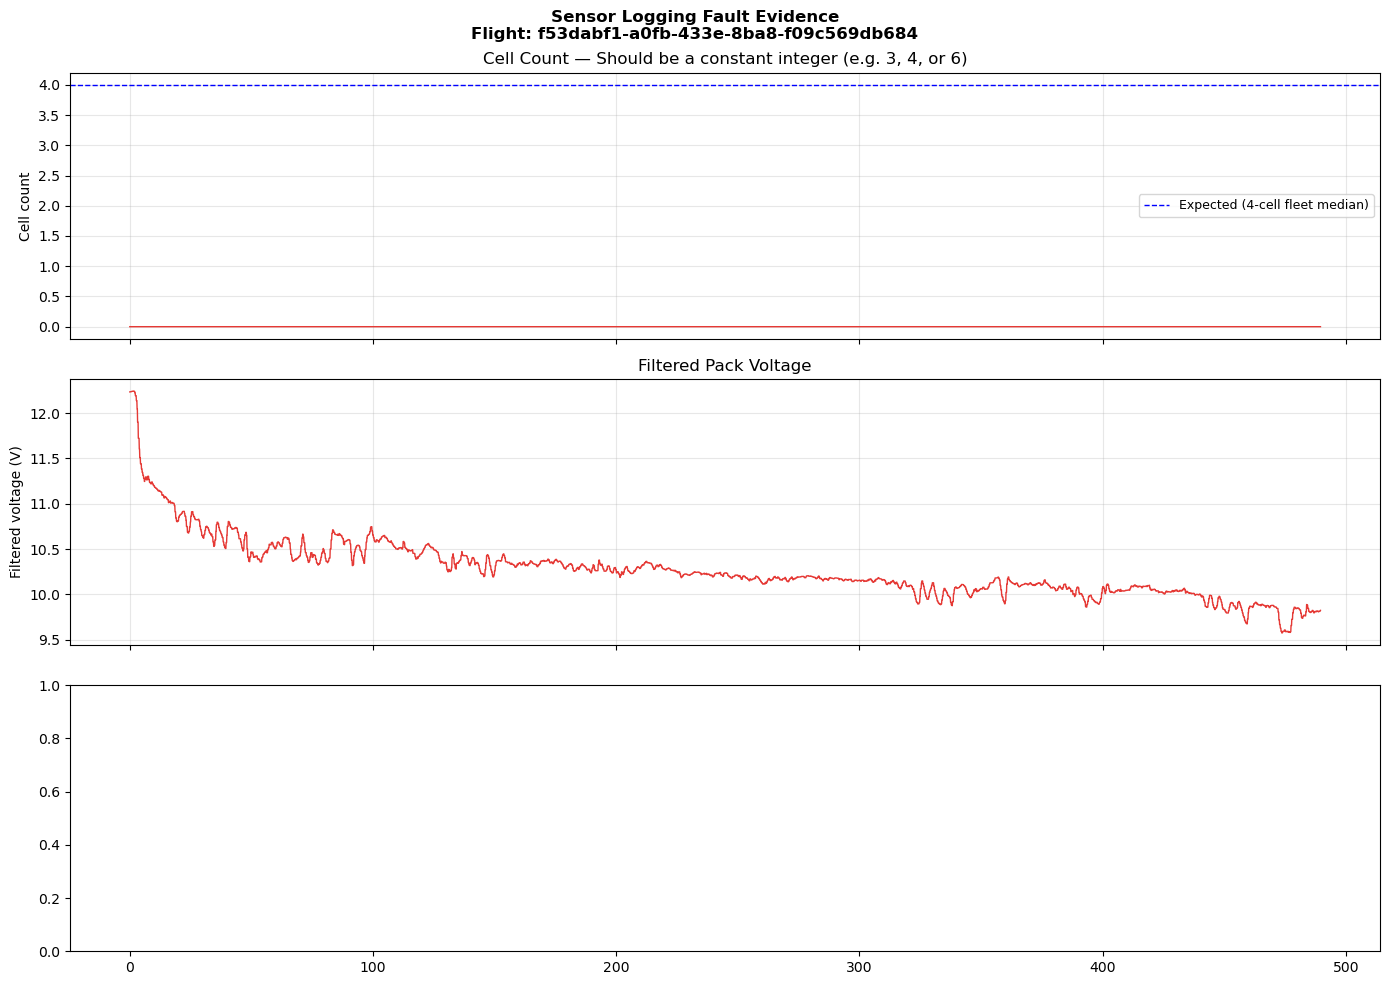

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/investigation_outputs/flight_removal/fault_flight_evidence.png


In [5]:
# ============================================================
# CELL 5: Time series plot showing the fault
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
fig.suptitle(
    f"Sensor Logging Fault Evidence\nFlight: {FAULT_FLIGHT_ID}",
    fontsize=12, fontweight="bold"
)

fault_sorted = fault_df.sort_values("time_s")
time = fault_sorted["time_s"]

# Panel 1: Cell count (should be constant integer)
ax = axes[0]
if "battery_status__cell_count" in fault_sorted.columns:
    ax.plot(time, fault_sorted["battery_status__cell_count"],
            color="#E53935", linewidth=1)
    ax.axhline(4, color="blue", linestyle="--", linewidth=1,
               label="Expected (4-cell fleet median)")
    ax.set_ylabel("Cell count")
    ax.set_title("Cell Count — Should be a constant integer (e.g. 3, 4, or 6)")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

# Panel 2: Voltage per cell
ax = axes[1]
if "voltage_per_cell" in fault_sorted.columns:
    ax.plot(time, fault_sorted["voltage_per_cell"],
            color="#E53935", linewidth=1, label="Faulty flight")
    ax.axhline(4.2, color="orange", linestyle="--",
               linewidth=1, label="Max LiPo (4.2 V)")
    ax.axhline(3.0, color="red",    linestyle="--",
               linewidth=1, label="Min LiPo (3.0 V)")
    ax.set_ylabel("Voltage per cell (V)")
    ax.set_title("Voltage Per Cell — Should be 3.0–4.2 V for LiPo")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
elif "battery_status__voltage_filtered_v" in fault_sorted.columns:
    ax.plot(time, fault_sorted["battery_status__voltage_filtered_v"],
            color="#E53935", linewidth=1)
    ax.set_ylabel("Filtered voltage (V)")
    ax.set_title("Filtered Pack Voltage")
    ax.grid(True, alpha=0.3)

# Panel 3: Suspicious flag
ax = axes[2]
if "voltage_per_cell_suspicious" in fault_sorted.columns:
    ax.fill_between(time,
                    fault_sorted["voltage_per_cell_suspicious"],
                    color="#E53935", alpha=0.7, label="Flagged suspicious")
    ax.set_ylabel("Suspicious flag")
    ax.set_title("Voltage Suspicious Flag — 1 = outside 3.0–4.2 V range")
    ax.set_ylim(-0.1, 1.3)
    ax.set_xlabel("Time (s)")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plot_path = OUTPUT_DIR / "fault_flight_evidence.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {plot_path}")

In [6]:
# ============================================================
# CELL 6: Written justification summary
# ============================================================

print("=" * 70)
print("EXCLUSION JUSTIFICATION STATEMENT")
print("=" * 70)
print(f"""
Flight ID: {FAULT_FLIGHT_ID}
Label in dataset: abnormal

EVIDENCE FOR EXCLUSION:

1. Cell count = 0 throughout entire flight
   - A UAV battery cannot have zero cells
   - This indicates the cell count field was never correctly populated
     in the PX4 telemetry log for this flight

2. Computed voltage per cell = 10.27 V (mean across entire flight)
   - Physically impossible for any lithium-based battery chemistry
   - LiPo operating range: 3.0 V (depleted) to 4.2 V (fully charged)
   - LiHV range: 3.0 V to 4.35 V
   - No lithium cell operates above ~4.5 V without catastrophic failure
   - The inflated value is a direct consequence of dividing pack voltage
     by a near-zero cell count (division by ~0 = very large number)

3. 100% of rows flagged as voltage_per_cell_suspicious
   - The voltage quality filter added in preprocessing notebook 02b
     flagged every single timestep in this flight
   - No other flight in the dataset approaches this flagging rate

CONCLUSION:
This flight suffers from a sensor logging fault in the cell count field.
The abnormal label assigned to this flight reflects the logging error,
not a genuine flight anomaly. It is excluded from all subsequent
modelling and evaluation on data quality grounds.

This exclusion is implemented in preprocessing notebook 02b_v2.
It does not affect any other flight in the dataset.
""")

# Save justification as text file
with open(OUTPUT_DIR / "exclusion_justification.txt", "w") as f:
    f.write(f"Flight excluded: {FAULT_FLIGHT_ID}\n")
    f.write("Reason: Sensor logging fault — cell count=0, voltage/cell=10.27V\n")
    f.write("Evidence: 100% of rows flagged as voltage_per_cell_suspicious\n")

print(f"Justification saved to: {OUTPUT_DIR / 'exclusion_justification.txt'}")

EXCLUSION JUSTIFICATION STATEMENT

Flight ID: f53dabf1-a0fb-433e-8ba8-f09c569db684
Label in dataset: abnormal

EVIDENCE FOR EXCLUSION:

1. Cell count = 0 throughout entire flight
   - A UAV battery cannot have zero cells
   - This indicates the cell count field was never correctly populated
     in the PX4 telemetry log for this flight

2. Computed voltage per cell = 10.27 V (mean across entire flight)
   - Physically impossible for any lithium-based battery chemistry
   - LiPo operating range: 3.0 V (depleted) to 4.2 V (fully charged)
   - LiHV range: 3.0 V to 4.35 V
   - No lithium cell operates above ~4.5 V without catastrophic failure
   - The inflated value is a direct consequence of dividing pack voltage
     by a near-zero cell count (division by ~0 = very large number)

3. 100% of rows flagged as voltage_per_cell_suspicious
   - The voltage quality filter added in preprocessing notebook 02b
     flagged every single timestep in this flight
   - No other flight in the dataset ap